# 04walknetwork: the walking network from OpenStreetMap (Stage 2, part 2 of 4)

Reads every footpath and street that people can walk on from the Geofabrik file, keeps the part inside
the search area (the seven districts plus 2 km), and saves it as two small tables:

- `walk_nodes.parquet`: the points where streets meet or bend (longitude, latitude)
- `walk_edges.parquet`: the street pieces between two points, with their length in metres

- Input: `data/raw/*.osm.pbf` (Geofabrik, Malaysia, Singapore and Brunei), `districts.geojson`
- Output: `data/processed/walk_nodes.parquet`, `walk_edges.parquet`, `walk_meta.json`, `output/stage2_network_preview.png`
- Next: `05access.ipynb`

## Section 0: settings

In [2]:
from pathlib import Path

BASE = Path.cwd()
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"

BUFFER_M = 2000        # same search area as 03services
METRIC_CRS = 32647     # UTM zone 47N, metres

# Street types people cannot (or should not) walk on. Everything else with a "highway" tag is kept,
# from footpaths and steps to residential streets and main roads (the same rule OSMnx uses for walking).
NOT_WALKABLE = {"motorway", "motorway_link", "construction", "proposed", "planned", "abandoned", "razed", "bus_guideway", "busway", "raceway", "cycleway", "platform", "corridor", "elevator", "no"}

EXPECTED_WAYS = 2_000_000   # about how many streets the Malaysia file has (only used for the progress line)

In [3]:
import json, math, time
from array import array
import numpy as np
import pandas as pd
import geopandas as gpd
import osmium
from IPython.display import display, HTML

pbf_files = sorted(RAW.glob("*.osm.pbf"))
assert pbf_files, "No .osm.pbf file found in data/raw"
PBF = pbf_files[-1]
header = osmium.io.Reader(str(PBF), osmium.osm.osm_entity_bits.NOTHING).header()
OSM_DATE = header.get("osmosis_replication_timestamp")
print("File:", PBF.name, "|", round(PBF.stat().st_size / 1e6), "MB | OpenStreetMap data as of", OSM_DATE)

File: malaysia-singapore-brunei-261006.osm.pbf | 252 MB | OpenStreetMap data as of 2026-10-06T20:21:06Z


## Step 1: the search area

In [4]:
districts = gpd.read_file(PROCESSED / "districts.geojson").to_crs(4326)
area_m = districts.to_crs(METRIC_CRS).union_all().buffer(BUFFER_M)
area = gpd.GeoSeries([area_m], crs=METRIC_CRS).to_crs(4326).iloc[0]
W, S, E, N = area.bounds
print("Search area: %.0f km2 | box %.2f to %.2f E, %.2f to %.2f N" % (area_m.area / 1e6, W, E, S, N))

Search area: 4294 km2 | box 101.20 to 101.99 E, 2.58 to 3.42 N


## Step 2: read the walkable streets

pyosmium goes through the whole file once (all of Malaysia, Singapore and Brunei) and keeps only street
pieces that touch the search box. This takes about 1 to 3 minutes. Streets are kept in both directions:
one-way rules are for cars, not for people walking.

Also dropped: streets marked `foot=no`, private roads (`access=private` or `service=private`) unless walking is allowed.

In [5]:
def walkable(tags):
    if tags.get("highway") in NOT_WALKABLE:
        return False
    foot = tags.get("foot")
    if foot in ("no", "private"):
        return False
    if tags.get("access") in ("private", "no") and foot not in ("yes", "designated", "permissive"):
        return False
    if tags.get("service") == "private":
        return False
    return True

def metres(lon1, lat1, lon2, lat2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 6371008.8 * 2 * math.asin(math.sqrt(a))

def in_box(lon, lat):
    return W <= lon <= E and S <= lat <= N

us, vs, lengths = array("q"), array("q"), array("f")
coords = {}
progress = display(HTML("<pre>starting ...</pre>"), display_id=True)
start, n_ways = time.time(), 0

processor = (osmium.FileProcessor(str(PBF), osmium.osm.NODE | osmium.osm.WAY)
             .with_locations()                                    # keeps node positions for the ways
             .with_filter(osmium.filter.EntityFilter(osmium.osm.WAY))
             .with_filter(osmium.filter.KeyFilter("highway")))
for way in processor:
    n_ways += 1
    if n_ways % 100_000 == 0:
        share = min(n_ways / EXPECTED_WAYS, 0.99)
        bar = "#" * int(30 * share) + "-" * (30 - int(30 * share))
        progress.update(HTML(f"<pre>[{bar}] about {100 * share:.0f}% | {n_ways:,} streets read, "
                             f"{len(us):,} pieces kept | {(time.time() - start) / 60:.1f} min</pre>"))
    if not walkable(way.tags):
        continue
    prev = None
    for nd in way.nodes:
        if not nd.location.valid():
            prev = None
            continue
        cur = (nd.ref, nd.location.lon, nd.location.lat)
        if prev is not None and (in_box(prev[1], prev[2]) or in_box(cur[1], cur[2])):
            us.append(prev[0]); vs.append(cur[0])
            lengths.append(metres(prev[1], prev[2], cur[1], cur[2]))
            coords[prev[0]] = (prev[1], prev[2]); coords[cur[0]] = (cur[1], cur[2])
        prev = cur

progress.update(HTML(f"<pre>[{'#' * 30}] done | {n_ways:,} streets read, {len(us):,} pieces kept | "
                     f"{(time.time() - start) / 60:.1f} min</pre>"))

## Step 3: keep only the search area, and only streets that connect

- Points outside the search area (inside the box but outside the shape) are dropped.
- Some footpaths are isolated: drawn in OSM without a link to any street (inside a condominium, a park,
  a mapping gap). A walk can never start or end there, so we keep only the **largest connected network**.

In [7]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

nodes = pd.DataFrame({"osm_id": np.fromiter(coords.keys(), dtype=np.int64)})
xy = np.array(list(coords.values()))
nodes["lon"], nodes["lat"] = xy[:, 0], xy[:, 1]
inside = gpd.GeoSeries(gpd.points_from_xy(nodes["lon"], nodes["lat"]), crs=4326).within(area).values
nodes = nodes[inside].reset_index(drop=True)

pos = pd.Series(np.arange(len(nodes)), index=nodes["osm_id"])
edges = pd.DataFrame({"u": np.frombuffer(us, dtype=np.int64), "v": np.frombuffer(vs, dtype=np.int64),
                      "length_m": np.frombuffer(lengths, dtype=np.float32)})
edges = edges[edges["u"].isin(pos.index) & edges["v"].isin(pos.index)]
edges["u"] = pos.loc[edges["u"]].values
edges["v"] = pos.loc[edges["v"]].values

n = len(nodes)
graph = coo_matrix((np.ones(len(edges)), (edges["u"], edges["v"])), shape=(n, n))
n_parts, part = connected_components(graph, directed=False)
main = np.bincount(part).argmax()
keep = part == main
print(f"{n:,} points in {n_parts:,} separate networks; the largest holds {100 * keep.mean():.1f}% of points")

# renumber the kept points 0, 1, 2, ...
new_id = np.full(n, -1, dtype=np.int64)
new_id[keep] = np.arange(keep.sum())
nodes = nodes[keep].reset_index(drop=True)
edges = edges[keep[edges["u"].values] & keep[edges["v"].values]].copy()
edges["u"] = new_id[edges["u"].values].astype(np.int32)
edges["v"] = new_id[edges["v"].values].astype(np.int32)
edges = edges[edges["u"] != edges["v"]].reset_index(drop=True)
print(f"Walking network: {len(nodes):,} points, {len(edges):,} street pieces, "
      f"{edges['length_m'].sum() / 1000:,.0f} km of walkable streets and paths")

1,305,322 points in 2,098 separate networks; the largest holds 96.8% of points
Walking network: 1,263,864 points, 1,400,833 street pieces, 38,664 km of walkable streets and paths


## Step 4: save

In [8]:
nodes.to_parquet(PROCESSED / "walk_nodes.parquet", index=False)
edges.to_parquet(PROCESSED / "walk_edges.parquet", index=False)
meta = {"source": PBF.name, "osm_date": OSM_DATE, "nodes": len(nodes), "edges": len(edges),
        "km": round(float(edges["length_m"].sum()) / 1000)}
(PROCESSED / "walk_meta.json").write_text(json.dumps(meta, indent=1))
for f in ["walk_nodes.parquet", "walk_edges.parquet", "walk_meta.json"]:
    print(f, round((PROCESSED / f).stat().st_size / 1e6, 1), "MB")

walk_nodes.parquet 27.2 MB
walk_edges.parquet 20.1 MB
walk_meta.json 0.0 MB


## Step 5: preview of the network

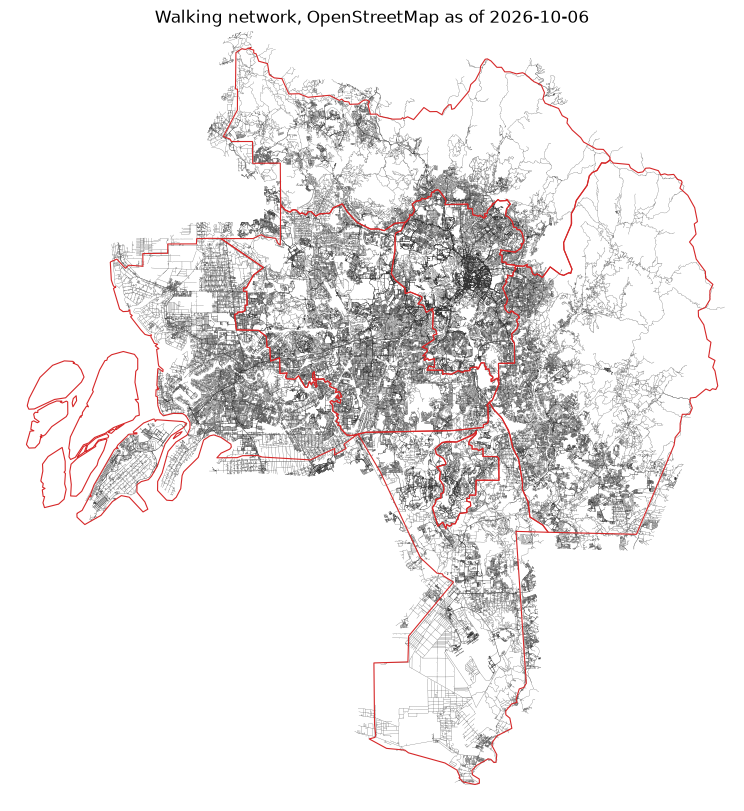

In [9]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

lon, lat = nodes["lon"].values, nodes["lat"].values
segments = np.stack([np.c_[lon[edges["u"]], lat[edges["u"]]], np.c_[lon[edges["v"]], lat[edges["v"]]]], axis=1)
fig, ax = plt.subplots(figsize=(10, 10), facecolor="white")
ax.add_collection(LineCollection(segments, linewidths=0.15, colors="#333333"))
districts.boundary.plot(ax=ax, color="#d62728", linewidth=0.8)
ax.set_xlim(W, E); ax.set_ylim(S, N); ax.set_aspect("equal"); ax.set_axis_off()
ax.set_title(f"Walking network, OpenStreetMap as of {OSM_DATE[:10]}")
plt.savefig(OUTPUT / "stage2_network_preview.png", dpi=110, bbox_inches="tight")
plt.show()

___
**END**